<a href="https://colab.research.google.com/github/anjali4593/BIS-lab/blob/main/Cuckoo_Search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best MSE: 0.05327539750750426
Testing Accuracy: 96.49122807017544 %


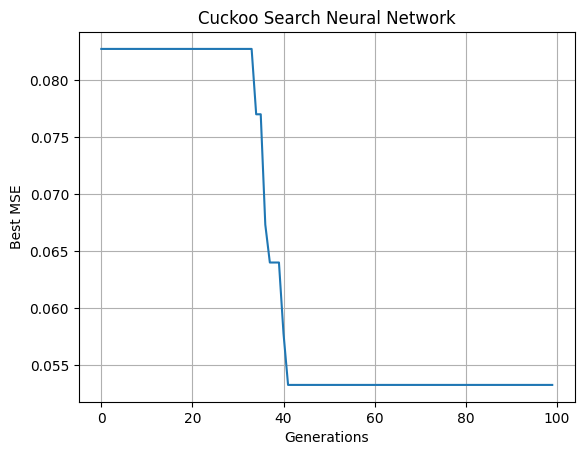

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import math

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load dataset
data = load_breast_cancer()
X, y = data.data, data.target.reshape(-1, 1)

X = StandardScaler().fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Neural network parameters
n_input = X.shape[1]
n_hidden = 5
dim = n_input*n_hidden + n_hidden + n_hidden + 1

def predict(X, w):
    i = n_input*n_hidden
    W1 = w[:i].reshape(n_input, n_hidden)
    b1 = w[i:i+n_hidden]
    W2 = w[i+n_hidden:i+2*n_hidden].reshape(n_hidden, 1)
    b2 = w[-1]
    h = np.tanh(X @ W1 + b1)
    return 1/(1 + np.exp(-np.clip(h @ W2 + b2, -500, 500)))

# 3. Fitness function
def fitness(w):
    return np.mean((y_train - predict(X_train, w))**2)

# 4. Lévy flight
def levy(beta=1.5):
    sigma = (
        math.gamma(1+beta)*np.sin(np.pi*beta/2) /
        (math.gamma((1+beta)/2)*beta*2**((beta-1)/2))
    )**(1/beta)
    u = np.random.normal(0, sigma, dim)
    v = np.random.normal(0, 1, dim)
    return u/(np.abs(v)**(1/beta)+1e-10)

# 5. Cuckoo Search
n, generations = 20, 100
nests = np.random.uniform(-1, 1, (n, dim))
scores = np.array([fitness(w) for w in nests])
best = nests[np.argmin(scores)].copy()
history = []

for t in range(generations):
    alpha = 0.5*(1-t/generations)
    Pa = 0.25

    for i in range(n):
        new = nests[i] + alpha*levy()*(nests[i]-best)
        new = np.clip(new, -2, 2)
        j = np.random.randint(n)

        if fitness(new) < scores[j]:
            nests[j] = new
            scores[j] = fitness(new)

    # Abandon worst nests
    worst = np.argsort(scores)[-int(Pa*n):]
    nests[worst] = np.random.uniform(-1, 1, (len(worst), dim))
    scores[worst] = [fitness(w) for w in nests[worst]]

    best = nests[np.argmin(scores)].copy()
    history.append(fitness(best))

# 6. Results
pred = (predict(X_test, best) >= 0.5).astype(int)
accuracy = np.mean(pred == y_test)*100

print("Best MSE:", fitness(best))
print("Testing Accuracy:", accuracy, "%")

# 7. Convergence graph
plt.plot(history)
plt.xlabel("Generations")
plt.ylabel("Best MSE")
plt.title("Cuckoo Search Neural Network")
plt.grid()
plt.show()
